In [5]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

from sklearn.decomposition import PCA

from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score,
    rand_score, adjusted_rand_score
)

from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import zscore

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
!wget -O Mall_Customers.csv https://raw.githubusercontent.com/Turbonik/AILab1/main/Mall_Customers.csv


--2026-11-09 07:22:09--  https://raw.githubusercontent.com/Turbonik/AILab1/main/Mall_Customers.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3981 (3.9K) [text/plain]
Saving to: ‘Mall_Customers.csv’

Mall_Customers.csv  100%[===================>]   3.89K  --.-KB/s    in 0s      

2026-11-09 07:22:09 (42.2 MB/s) - ‘Mall_Customers.csv’ saved [3981/3981]



=== 1. Первые 5 строк ===


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



=== 2. Размерность ===
Строк: 200, Столбцов: 5

=== 3. Типы данных и пропуски ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

=== 4. Базовая статистика ===


,count,mean,std,min,25%,50%,75%,max
CustomerID,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0



=== 5. Гистограммы ===


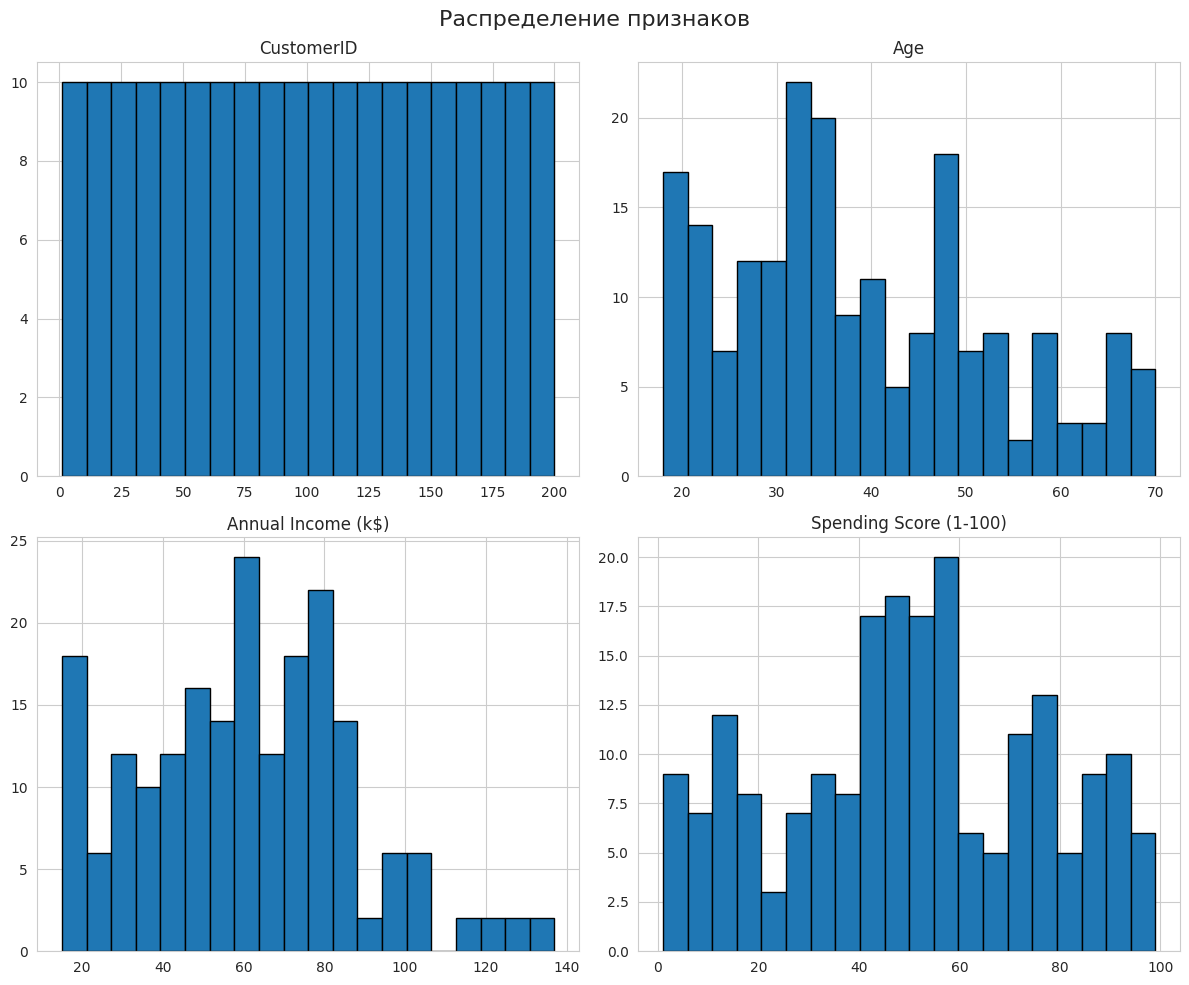


=== 6. Поиск выбросов (Boxplot) ===


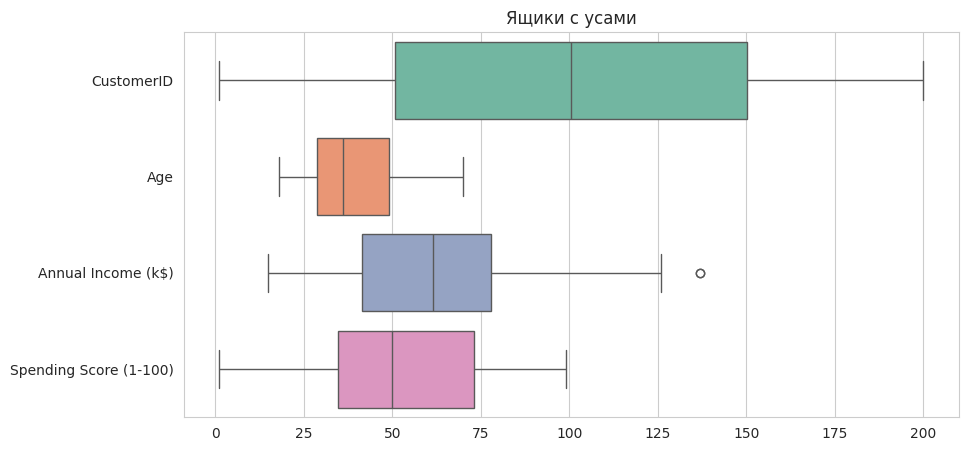

In [6]:
df = pd.read_csv("Mall_Customers.csv")

print("=== 1. Первые 5 строк ===")
display(df.head())

print("\n=== 2. Размерность ===")
print(f"Строк: {df.shape[0]}, Столбцов: {df.shape[1]}")

print("\n=== 3. Типы данных и пропуски ===")
print(df.info())

print("\n=== 4. Базовая статистика ===")
display(df.describe().T)

print("\n=== 5. Гистограммы ===")
df.hist(figsize=(12, 10), bins=20, edgecolor='black')
plt.suptitle('Распределение признаков', fontsize=16)
plt.tight_layout()
plt.show()

print("\n=== 6. Поиск выбросов (Boxplot) ===")
plt.figure(figsize=(10, 5))
sns.boxplot(data=df.select_dtypes(include=np.number), orient="h", palette="Set2")
plt.title('Ящики с усами')
plt.show()